## Ejercicio hiperparametrización breast cancer de sklearn

1. Carga el dataset [breast_cancer de `sklearn`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
2. Prueba al menos 5 modelos diferentes de clasificación y aplica un GridSearchCV mediante Pipelines. Aplica también un RandomizedSearchCV.
3. Conclusiones. Guarda el modelo final en un archivo con pickle.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

In [ ]:
# carga data set

%matplotlib inline
data = load_breast_cancer()
data

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]], shape=(569, 30)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,

In [3]:
data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [4]:
print(data['DESCR'])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [5]:
df = pd.DataFrame(data['data'], columns=data['feature_names'])
df['target'] = data['target']
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [6]:
# Entender la variable modelo

data.target_names

array(['malignant', 'benign'], dtype='<U9')

In [7]:
# mini EDA

df.shape

(569, 31)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [ ]:
df. describe(). T

# T, cambia las columnas por filas

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [11]:
# valores nulos

df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [12]:
# duplicados 

df.duplicated().sum()

np.int64(0)

In [13]:
# distribución de la variable objetivo

df['target'].value_counts()

target
1    357
0    212
Name: count, dtype: int64

In [14]:
df['target'].value_counts(normalize=True) * 100

target
1    62.741652
0    37.258348
Name: proportion, dtype: float64

In [15]:
# dividir en X e Y
X = df.drop(columns=['target'])
y = df['target']

In [ ]:
# Train Test Split
# Dividimos los datos en entrenamiento (80 %) y test (20 %)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Se utiliza stratify = y porque hay más tumores benignos que malignos.
# Con stratify se mantiene aproximadamente la misma proporción de ambas clases en entrenamiento y test.

**PRIMER MODELO: CLASIFICACION (Regresión logistica)

In [17]:
# Clasificación

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report

In [18]:
# Crear el Pipeline

pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=5000))
])

In [19]:
# Entrenar el modelo sin optimizar
# Primero entrenamos el modelo con sus hiperparámetros por defecto para tener una referencia con la que comparar posteriormente.

pipe_lr.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [20]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    pipe_lr, X_train, y_train,
    cv=5,
    scoring='accuracy'
)

print('Accuracy media:', scores.mean())

Accuracy media: 0.9802197802197803


In [22]:
# Hiperparametrización con GridSearchCV
# Definir los hiperparámetros que queremos probar

param_grid_lr = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__solver': ['liblinear', 'lbfgs']
}

# C: Controla la intensidad inversa de la regularización.
# solver: Algoritmo utilizado para optimizar el modelo.
# max_iter:	Número máximo de iteraciones.

In [23]:
# Crear el GridSearchCV

grid_lr = GridSearchCV(
    estimator=pipe_lr,
    param_grid=param_grid_lr,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

In [24]:
# Entrenar el GridSearchCV

grid_lr.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=5000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__solver': ['liblinear', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosit

In [25]:
# Obtener los mejores resultados

print('Mejores hiperparámetros:', grid_lr.best_params_)
print('Mejor accuracy:', grid_lr.best_score_)

Mejores hiperparámetros: {'model__C': 0.1, 'model__solver': 'liblinear'}
Mejor accuracy: 0.9802197802197803


In [26]:
resultados_lr = pd.DataFrame(grid_lr.cv_results_)

resultados_lr[['params', 'mean_test_score', 'rank_test_score']].sort_values('rank_test_score')

,params,mean_test_score,rank_test_score
3,"{'model__C': 0.1, 'model__solver': 'lbfgs'}",0.980220,1
2,"{'model__C': 0.1, 'model__solver': 'liblinear'}",0.980220,1
5,"{'model__C': 1, 'model__solver': 'lbfgs'}",0.980220,1
4,"{'model__C': 1, 'model__solver': 'liblinear'}",0.980220,1
0,"{'model__C': 0.01, 'model__solver': 'liblinear'}",0.971429,5
6,"{'model__C': 10, 'model__solver': 'liblinear'}",0.969231,6
7,"{'model__C': 10, 'model__solver': 'lbfgs'}",0.969231,6
9,"{'model__C': 100, 'model__solver': 'lbfgs'}",0.956044,8
8,"{'model__C': 100, 'model__solver': 'liblinear'}",0.953846,9
1,"{'model__C': 0.01, 'model__solver': 'lbfgs'}",0.951648,10


In [27]:
# Comparar el modelo inicial con el optimizado
# ¿La hiperparametrización ha conseguido mejorar el modelo inicial?

print('Accuracy modelo inicial:', scores.mean())
print('Accuracy modelo optimizado:', grid_lr.best_score_)
print('Mejores hiperparámetros:', grid_lr.best_params_)

Accuracy modelo inicial: 0.9802197802197803
Accuracy modelo optimizado: 0.9802197802197803
Mejores hiperparámetros: {'model__C': 0.1, 'model__solver': 'liblinear'}


In [29]:
# Guardar el mejor modelo de Logistic Regression

best_lr = grid_lr.best_estimator_

** SEGUNDO MODELO: KNN

In [30]:
# Segundo modelo: K-Nearest Neighbors (KNN)

from sklearn.neighbors import KNeighborsClassifier

In [31]:
# Crear el Pipeline

pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier())
])

In [32]:
# Evaluar el modelo inicial

scores_knn = cross_val_score(
    pipe_knn,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print('Accuracy modelo inicial:', scores_knn.mean())

Accuracy modelo inicial: 0.9670329670329669


In [33]:
# Definir hiperparámetros

param_grid_knn = {
    'model__n_neighbors': [3, 5, 7, 9, 11, 15],
    'model__weights': ['uniform', 'distance'],
    'model__metric': ['euclidean', 'manhattan']
}

In [34]:
# Aplicar GridSearchCV

grid_knn = GridSearchCV(
    estimator=pipe_knn,
    param_grid=param_grid_knn,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_knn.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__metric': ['euclidean', 'manhattan'], 'model__n_neighbors': [3, 5, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"

In [35]:
# Resultados

print('Accuracy modelo inicial:', scores_knn.mean())
print('Accuracy modelo optimizado:', grid_knn.best_score_)
print('Mejores hiperparámetros:', grid_knn.best_params_)

Accuracy modelo inicial: 0.9670329670329669
Accuracy modelo optimizado: 0.9714285714285715
Mejores hiperparámetros: {'model__metric': 'euclidean', 'model__n_neighbors': 7, 'model__weights': 'uniform'}


In [36]:
resultados_knn = pd.DataFrame(grid_knn.cv_results_)

resultados_knn[
    ['params', 'mean_test_score', 'rank_test_score']
].sort_values('rank_test_score')

,params,mean_test_score,rank_test_score
5,"{'model__metric': 'euclidean', 'model__n_neigh...",0.971429,1
4,"{'model__metric': 'euclidean', 'model__n_neigh...",0.971429,1
0,"{'model__metric': 'euclidean', 'model__n_neigh...",0.969231,3
1,"{'model__metric': 'euclidean', 'model__n_neigh...",0.969231,3
6,"{'model__metric': 'euclidean', 'model__n_neigh...",0.969231,3
7,"{'model__metric': 'euclidean', 'model__n_neigh...",0.969231,3
3,"{'model__metric': 'euclidean', 'model__n_neigh...",0.967033,7
2,"{'model__metric': 'euclidean', 'model__n_neigh...",0.967033,7
11,"{'model__metric': 'euclidean', 'model__n_neigh...",0.967033,7
14,"{'model__metric': 'manhattan', 'model__n_neigh...",0.967033,7


In [38]:
best_knn = grid_knn.best_estimator_

** TERCER MODELO: DECISION TREE

In [39]:
# Tercer modelo: Decision Tree

from sklearn.tree import DecisionTreeClassifier

In [ ]:
# Crear Pipeline

pipe_dt = Pipeline([
    ('model', DecisionTreeClassifier(random_state=42))
])

# los árboles de decisión no necesitan estandarizar los datos, ya que realizan divisiones mediante umbrales y no calculan distancias entre observaciones.

In [41]:
# Evaluar modelo inicial

scores_dt = cross_val_score(
    pipe_dt,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print('Accuracy modelo inicial:', scores_dt.mean())

Accuracy modelo inicial: 0.9098901098901099


In [42]:
# Definir hiperparámetros

param_grid_dt = {
    'model__criterion': ['gini', 'entropy'],
    'model__max_depth': [3, 5, 7, 10, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

In [43]:
# Aplicar GridSearchCV

grid_dt = GridSearchCV(
    estimator=pipe_dt,
    param_grid=param_grid_dt,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_dt.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__criterion': ['gini', 'entropy'], 'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Supp

In [ ]:
# Resultados

print('Accuracy modelo inicial:', scores_dt.mean())
print('Accuracy modelo optimizado:', grid_dt.best_score_)
print('Mejores hiperparámetros:', grid_dt.best_params_)

Accuracy modelo inicial: 0.9098901098901099
Accuracy modelo optimizado: 0.9384615384615385
Mejores hiperparámetros: {'model__criterion': 'gini', 'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5}


In [45]:
resultados_dt = pd.DataFrame(grid_dt.cv_results_)

resultados_dt[
    ['params', 'mean_test_score', 'rank_test_score']
].sort_values('rank_test_score').head(10)

,params,mean_test_score,rank_test_score
10,"{'model__criterion': 'gini', 'model__max_depth...",0.938462,1
11,"{'model__criterion': 'gini', 'model__max_depth...",0.936264,2
13,"{'model__criterion': 'gini', 'model__max_depth...",0.934066,3
15,"{'model__criterion': 'gini', 'model__max_depth...",0.934066,3
24,"{'model__criterion': 'gini', 'model__max_depth...",0.934066,3
25,"{'model__criterion': 'gini', 'model__max_depth...",0.934066,3
16,"{'model__criterion': 'gini', 'model__max_depth...",0.934066,3
33,"{'model__criterion': 'gini', 'model__max_depth...",0.934066,3
43,"{'model__criterion': 'gini', 'model__max_depth...",0.934066,3
42,"{'model__criterion': 'gini', 'model__max_depth...",0.934066,3


In [46]:
# Almacenar el mejor modelo

best_dt = grid_dt.best_estimator_

** CUARTO MODELO: RANDOM FOREST

In [47]:
# Cuarto modelo Random Forest
# Algoritmo de tipo ensemble, combina varios modelos para obtener una predicción conjunta.

from sklearn.ensemble import RandomForestClassifier

In [48]:
# Crear Pipeline

pipe_rf = Pipeline([
    ('model', RandomForestClassifier(random_state=42))
])

In [49]:
# Evaluar modelo inicial

scores_rf = cross_val_score(
    pipe_rf,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print('Accuracy modelo inicial:', scores_rf.mean())

Accuracy modelo inicial: 0.953846153846154


In [50]:
# definir hiperparámetros

param_grid_rf = {
    'model__n_estimators': [50, 100, 200],
    'model__max_depth': [3, 5, 10, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

In [51]:
# Aplicar GridSearchCV

grid_rf = GridSearchCV(
    estimator=pipe_rf,
    param_grid=param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], 'model__n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Suppor

In [52]:
# Resultados

print('Accuracy modelo inicial:', scores_rf.mean())
print('Accuracy modelo optimizado:', grid_rf.best_score_)
print('Mejores hiperparámetros:', grid_rf.best_params_)

Accuracy modelo inicial: 0.953846153846154
Accuracy modelo optimizado: 0.9604395604395606
Mejores hiperparámetros: {'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}


In [53]:
resultados_rf = pd.DataFrame(grid_rf.cv_results_)

resultados_rf[
    ['params', 'mean_test_score', 'rank_test_score']
].sort_values('rank_test_score').head(10)

,params,mean_test_score,rank_test_score
56,"{'model__max_depth': 10, 'model__min_samples_l...",0.960440,1
93,"{'model__max_depth': None, 'model__min_samples...",0.960440,1
79,"{'model__max_depth': 10, 'model__min_samples_l...",0.960440,1
106,"{'model__max_depth': None, 'model__min_samples...",0.960440,1
83,"{'model__max_depth': None, 'model__min_samples...",0.960440,1
66,"{'model__max_depth': 10, 'model__min_samples_l...",0.960440,1
38,"{'model__max_depth': 5, 'model__min_samples_le...",0.958242,7
63,"{'model__max_depth': 10, 'model__min_samples_l...",0.958242,7
90,"{'model__max_depth': None, 'model__min_samples...",0.958242,7
73,"{'model__max_depth': 10, 'model__min_samples_l...",0.958242,7


In [54]:
# Almacenar mejor modelo

best_rf = grid_rf.best_estimator_

**Quinto modelo: Support Vector Machine (SVM)

In [55]:
from sklearn.svm import SVC

In [56]:
# Crear el pipeline

pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC())
])

In [57]:
# Evaluar el modelo inicial

scores_svm = cross_val_score(
    pipe_svm,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print('Accuracy modelo inicial:', scores_svm.mean())

Accuracy modelo inicial: 0.9714285714285715


In [58]:
# Definir hiperparámetros

param_grid_svm = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__kernel': ['linear', 'rbf', 'poly'],
    'model__gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

In [59]:
# Aplicar GridSearchCV

grid_svm = GridSearchCV(
    estimator=pipe_svm,
    param_grid=param_grid_svm,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_svm.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...del', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__gamma': ['scale', 'auto', ...], 'model__kernel': ['linear', 'rbf', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose ve

In [60]:
# Resultados

print('Accuracy modelo inicial:', scores_svm.mean())
print('Accuracy modelo optimizado:', grid_svm.best_score_)
print('Mejores hiperparámetros:', grid_svm.best_params_)

Accuracy modelo inicial: 0.9714285714285715
Accuracy modelo optimizado: 0.9802197802197803
Mejores hiperparámetros: {'model__C': 10, 'model__gamma': 0.01, 'model__kernel': 'rbf'}


In [61]:
resultados_svm = pd.DataFrame(grid_svm.cv_results_)

resultados_svm[
    ['params', 'mean_test_score', 'rank_test_score']
].sort_values('rank_test_score').head(10)

,params,mean_test_score,rank_test_score
52,"{'model__C': 10, 'model__gamma': 0.01, 'model_...",0.980220,1
15,"{'model__C': 0.1, 'model__gamma': 'scale', 'mo...",0.978022,2
21,"{'model__C': 0.1, 'model__gamma': 0.01, 'model...",0.978022,2
27,"{'model__C': 0.1, 'model__gamma': 1, 'model__k...",0.978022,2
24,"{'model__C': 0.1, 'model__gamma': 0.1, 'model_...",0.978022,2
18,"{'model__C': 0.1, 'model__gamma': 'auto', 'mod...",0.978022,2
6,"{'model__C': 0.01, 'model__gamma': 0.01, 'mode...",0.973626,7
0,"{'model__C': 0.01, 'model__gamma': 'scale', 'm...",0.973626,7
9,"{'model__C': 0.01, 'model__gamma': 0.1, 'model...",0.973626,7
12,"{'model__C': 0.01, 'model__gamma': 1, 'model__...",0.973626,7


In [62]:
# Almacenar mejor modelo

best_svm = grid_svm.best_estimator_

Se utiliza Random Forest
Ha sido el modelo con mayor número de combinaciones y permitirá comparar la eficiencia de ambas técnicas

In [63]:
from sklearn.model_selection import RandomizedSearchCV

In [64]:
# Definir hiperparámetros

param_dist_rf = {
    'model__n_estimators': [50, 100, 200],
    'model__max_depth': [3, 5, 10, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

In [65]:
# Crear el RandomizedSearchCV
# Se reutiliza el Pipeline de Random Forest

random_rf = RandomizedSearchCV(
    estimator=pipe_rf,
    param_distributions=param_dist_rf,
    n_iter=20,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

In [66]:
# entrenar el modelo

random_rf.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], 'model__n_estimators': [50, 100, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSear

In [67]:
print('Mejores hiperparámetros:', random_rf.best_params_)
print('Mejor accuracy:', random_rf.best_score_)

Mejores hiperparámetros: {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': None}
Mejor accuracy: 0.9604395604395606


In [68]:
resultados_random_rf = pd.DataFrame(random_rf.cv_results_)

resultados_random_rf[
    ['params', 'mean_test_score', 'rank_test_score']
].sort_values('rank_test_score').head(10)

,params,mean_test_score,rank_test_score
3,"{'model__n_estimators': 200, 'model__min_sampl...",0.960440,1
11,"{'model__n_estimators': 100, 'model__min_sampl...",0.960440,1
18,"{'model__n_estimators': 100, 'model__min_sampl...",0.960440,1
16,"{'model__n_estimators': 200, 'model__min_sampl...",0.960440,1
17,"{'model__n_estimators': 100, 'model__min_sampl...",0.958242,5
8,"{'model__n_estimators': 200, 'model__min_sampl...",0.956044,6
5,"{'model__n_estimators': 100, 'model__min_sampl...",0.953846,7
0,"{'model__n_estimators': 200, 'model__min_sampl...",0.953846,7
13,"{'model__n_estimators': 200, 'model__min_sampl...",0.953846,7
15,"{'model__n_estimators': 50, 'model__min_sample...",0.953846,7


In [69]:
# Comparar GridSearchCV con RandomizedSearchCV

print('Accuracy GridSearchCV:', grid_rf.best_score_)
print('Accuracy RandomizedSearchCV:', random_rf.best_score_)

Accuracy GridSearchCV: 0.9604395604395606
Accuracy RandomizedSearchCV: 0.9604395604395606


In [70]:
# Crear un DataFrame comparativo de todos los modelos

resultados = pd.DataFrame({
    'Modelo': [
        'Logistic Regression',
        'KNN',
        'Decision Tree',
        'Random Forest',
        'SVM',
        'Random Forest (Randomized)'
    ],

    'Accuracy inicial': [
        scores.mean(),
        scores_knn.mean(),
        scores_dt.mean(),
        scores_rf.mean(),
        scores_svm.mean(),
        scores_rf.mean()
    ],

    'Accuracy optimizado': [
        grid_lr.best_score_,
        grid_knn.best_score_,
        grid_dt.best_score_,
        grid_rf.best_score_,
        grid_svm.best_score_,
        random_rf.best_score_
    ]
})

resultados['Mejora'] = (
    resultados['Accuracy optimizado'] -
    resultados['Accuracy inicial']
)

resultados = resultados.sort_values(
    'Accuracy optimizado', ascending=False
)

resultados

,Modelo,Accuracy inicial,Accuracy optimizado,Mejora
0,Logistic Regression,0.980220,0.980220,0.000000
4,SVM,0.971429,0.980220,0.008791
1,KNN,0.967033,0.971429,0.004396
3,Random Forest,0.953846,0.960440,0.006593
5,Random Forest (Randomized),0.953846,0.960440,0.006593
2,Decision Tree,0.909890,0.938462,0.028571


Tras entrenar cinco modelos de clasificación y optimizar sus hiperparámetros mediante GridSearchCV, se observa:

- Logistic Regression y SVM son los modelos con mayor accuracy en validación cruzada, alcanzando un 98,02 %.

- Decision Tree es el modelo que más se beneficia de la hiperparametrización, con una mejora de 2,86 puntos porcentuales.

- Logistic Regression mantiene su rendimiento inicial, lo que indica que sus hiperparámetros por defecto ya eran adecuados.

- RandomizedSearchCV consigue el mismo accuracy que GridSearchCV en Random Forest, reduciendo el número de entrenamientos en validación cruzada un 81,48 %.

La hiperparametrización permite mejorar el rendimiento de la mayoría de los modelos, aunque su impacto varía en función del algoritmo utilizado.

In [73]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer
from sklearn.metrics import precision_score, recall_score, f1_score

In [ ]:
# Definir métricas

metricas = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, pos_label=0),
    'recall': make_scorer(recall_score, pos_label=0),
    'f1': make_scorer(f1_score, pos_label=0)
}

# se quiere detectar la clase 0, la maligna

In [75]:
# Evaluar Logistic Regression

metricas_lr = cross_validate(
    best_lr,
    X_train,
    y_train,
    cv=5,
    scoring=metricas
)

In [ ]:
# Evaluar SVM

metricas_svm = cross_validate(
    best_svm,
    X_train,
    y_train,
    cv=5,
    scoring=metricas
)

# Se utiliza cross_validate en lugar de cross_val_score porque se quiere evaluar varias métricas simultáneamente.

In [77]:
# Crear el DataFrame comparacion_final

comparacion_final = pd.DataFrame({
    'Logistic Regression': {
        'Accuracy': metricas_lr['test_accuracy'].mean(),
        'Precision': metricas_lr['test_precision'].mean(),
        'Recall': metricas_lr['test_recall'].mean(),
        'F1-score': metricas_lr['test_f1'].mean()
    },
    'SVM': {
        'Accuracy': metricas_svm['test_accuracy'].mean(),
        'Precision': metricas_svm['test_precision'].mean(),
        'Recall': metricas_svm['test_recall'].mean(),
        'F1-score': metricas_svm['test_f1'].mean()
    }
}).T


In [ ]:
# Evaluar recall de la clase maligna, debido a la importancia de detectar correctamente este tipo de tumores.
comparacion_final

,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.98022,0.982857,0.964706,0.973205
SVM,0.98022,0.988571,0.958824,0.972834


- Accuracy: ambos modelos tienen la misma proporción de aciertos.
- Precision: SVM comete proporcionalmente menos errores al predecir tumores malignos.
- Recall: Logistic Regression consigue detectar una mayor proporción de los tumores realmente malignos.
- F1-score: Logistic Regression presenta un equilibrio ligeramente superior entre precision y recall.

In [79]:
# Selección de Logistic Regression
# Motivos
# - Obtiene el máximo accuracy en validación cruzada.
# - Presenta un mayor recall de la clase maligna.
# - Obtiene un F1-score ligeramente superior.
# - Es un modelo más sencillo e interpretable.

modelo_final = best_lr

print(modelo_final)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(C=0.1, max_iter=5000, solver='liblinear'))])


In [80]:
# Predecir con el uso de test

y_pred = modelo_final.predict(X_test)

In [81]:
# evaluar métricas

print('Accuracy:', accuracy_score(y_test, y_pred))

print('Precision:', precision_score(y_test, y_pred, pos_label=0))

print('Recall:', recall_score(y_test, y_pred, pos_label=0))

print('F1-score:', f1_score(y_test, y_pred, pos_label=0))

Accuracy: 0.9824561403508771
Precision: 0.9761904761904762
Recall: 0.9761904761904762
F1-score: 0.9761904761904762


In [82]:
# Clasification report

print(classification_report(
    y_test,
    y_pred,
    target_names=['Maligno', 'Benigno']
))

              precision    recall  f1-score   support

     Maligno       0.98      0.98      0.98        42
     Benigno       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



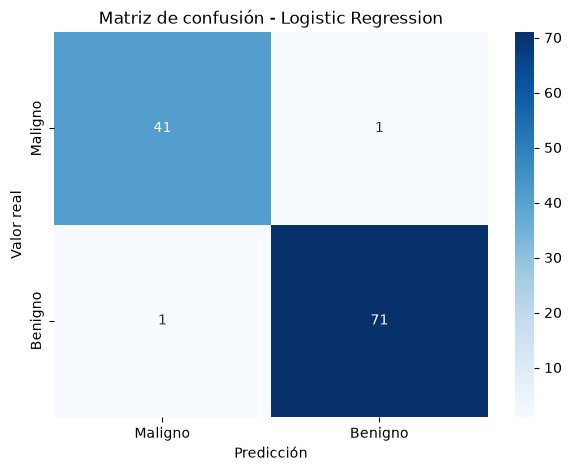

In [84]:
# Matriz de confusión:permitirá conocer exactamente cuántos tumores se han clasificado correctamente y en cuántos se equivoca.

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Maligno', 'Benigno'],
    yticklabels=['Maligno', 'Benigno']
)

plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title('Matriz de confusión - Logistic Regression')
plt.show()

In [85]:
# Guardar en Pickle

import pickle

with open('modelo_breast_cancer.pkl', 'wb') as archivo:
    pickle.dump(modelo_final, archivo)

** Conclusiones

El objetivo del ejercicio ha sido entrenar y comparar diferentes modelos de clasificación para predecir si un tumor de mama es maligno o benigno, aplicando técnicas de hiperparametrización para optimizar su rendimiento.

** Comparación de modelos

Se han evaluado cinco algoritmos de clasificación: Logistic Regression, K-Nearest Neighbors, Decision Tree, Random Forest y Support Vector Machine, utilizando Pipelines y validación cruzada de cinco particiones.

Se han escogido estos modelos por los siguientes motivos:

- Logistic Regression — modelo lineal: sencillo, rápido e interpretable. Se utiliza como modelo de referencia para comprobar si una solución sencilla es suficiente para clasificar correctamente los tumores.

- KNN — modelo basado en distancias: Permite comprobar si los tumores que presentan características similares pertenecen a la misma clase.

- Decision Tree — modelo basado en reglas: Permite identificar relaciones no lineales y clasificar los tumores mediante reglas de decisión. Es especialmente interesante para estudiar cómo la hiperparametrización ayuda a controlar el sobreajuste.

- Random Forest — modelo de conjunto (Ensemble): Combina múltiples árboles de decisión. Se elige para comprobar si la combinación de árboles mejora la estabilidad y la capacidad de generalización de Decision Tree.

- SVM — modelo basado en márgenes: Busca la frontera de decisión que mejor separa las clases.Mediante los kernels permite explorar relaciones lineales y no lineales.

** Selección del modelo final

- Se selecciona Logistic Regression como modelo final debido a su elevado accuracy, su sencillez, su interpretabilidad y su mayor recall de la clase maligna frente a SVM.

- Se prioriza el recall porque, en el contexto de la clasificación de tumores, resulta especialmente importante minimizar los falsos negativos.

De las 114 observaciones evaluadas, el modelo clasifica correctamente 112, cometiendo únicamente un falso positivo y un falso negativo.

La similitud entre los resultados obtenidos en validación cruzada y test indica una buena capacidad de generalización, sin indicios evidentes de sobreajuste.

** Mejora 

Se podría optimizar directamente el recall de la clase maligna, ajustar el umbral de clasificación y realizar una validación con datos externos. 